# Hospital Patient Care Analytics Pipeline

## 1. Problem Understanding

A multi-specialty hospital collects patient information from different sources such as patient registration, appointment scheduling, laboratory reports, wearable health devices, and doctor consultation notes.

The main challenge is to bring all this information together and make it useful for hospital management and authorized personnel.

The hospital wants to:
- Reduce patient waiting time
- Improve appointment management
- Analyze patient-care information
- Identify high-risk patients
- Improve overall operational efficiency

## 2. Data Sources

The hospital receives data from five major sources:

1. Patient Registration
2. Appointment Scheduling
3. Laboratory Reports
4. Wearable Health Devices
5. Doctor Consultation Notes

### 2.1 Patient Registration

Contains basic patient information such as Patient ID, age, gender, and registration details.

Patient ID is used as the common identifier that connects a patient's records across the other hospital systems.

### 2.2 Appointment Scheduling

Contains appointment information such as Patient ID, Doctor, department, appointment date, scheduled time, and appointment status.

This data is used to analyze appointment availability, cancellations, waiting time, and slot utilization.

### 2.3 Laboratory Reports

Contains laboratory test information and results.

This data can be combined with other patient information for further analysis.

### 2.4 Wearable Health Devices

Wearable devices continuously generate health measurements such as heart rate and SpO2.

Since this data can arrive continuously, it can be processed using a streaming approach.

### 2.5 Doctor Consultation Notes

Contains information such as symptoms, diagnosis, prescriptions, and observations.

This information provides additional context about the patient's treatment history.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CHART_COLOR = "orange"

## 3. Load the Hospital Dataset

The hospital data is stored in a CSV file. I will load the dataset using Pandas and inspect its structure before starting the data cleaning and analysis process.

In [2]:
df = pd.read_csv("hospital_patient_care_dataset.csv")

df.head()

,patient_id,patient_name,age,gender,department,doctor,appointment_date,scheduled_time,actual_consultation_time,appointment_status,lab_test,lab_result,spo2,heart_rate,diagnosis
0,2001,Aarav,29,M,General Medicine,Dr. Verma,2026-09-21,09:40,10:13,Booked,Glucose,169.5,97,77,Pre-Diabetes
1,2002,Diya,35,M,General Medicine,Dr. Verma,2026-09-21,10:30,10:42,Completed,Cholesterol,233.2,92,102,High Cholesterol
2,2003,Rohan,76,F,General Medicine,Dr. Verma,2026-09-21,10:50,11:15,Cancelled,Cholesterol,199.7,99,94,High Cholesterol
3,2004,Ananya,24,M,Neurology,Dr. Sharma,2026-09-21,10:30,10:51,Cancelled,Glucose,180.2,98,105,Hypertension
4,2005,Vikram,68,F,Cardiology,Dr. Nair,2026-09-21,11:30,12:08,Cancelled,Glucose,179.9,93,100,Hypertension


## 4. Understanding the Dataset

The dataset contains information related to patients, appointments, doctors, laboratory results, wearable health measurements, and diagnoses.

Before processing the data, I will check the number of records, columns, data types, and missing values.

In [3]:
df.shape

(20, 15)

In [4]:
df.columns

Index(['patient_id', 'patient_name', 'age', 'gender', 'department', 'doctor',
       'appointment_date', 'scheduled_time', 'actual_consultation_time',
       'appointment_status', 'lab_test', 'lab_result', 'spo2', 'heart_rate',
       'diagnosis'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                20 non-null     int64  
 1   patient_name              20 non-null     str    
 2   age                       20 non-null     int64  
 3   gender                    20 non-null     str    
 4   department                20 non-null     str    
 5   doctor                    20 non-null     str    
 6   appointment_date          20 non-null     str    
 7   scheduled_time            20 non-null     str    
 8   actual_consultation_time  20 non-null     str    
 9   appointment_status        20 non-null     str    
 10  lab_test                  20 non-null     str    
 11  lab_result                20 non-null     float64
 12  spo2                      20 non-null     int64  
 13  heart_rate                20 non-null     int64  
 14  diagnosis              

In [6]:
df.describe()

,patient_id,age,lab_result,spo2,heart_rate
count,20.00000,20.00000,20.000000,20.000000,20.000000
mean,2010.50000,57.25000,157.255000,93.800000,99.150000
std,5.91608,17.95572,78.588224,3.518373,10.873798
min,2001.00000,24.00000,12.200000,89.000000,77.000000
25%,2005.75000,49.25000,146.825000,90.750000,93.750000
50%,2010.50000,65.00000,180.050000,93.500000,100.500000
75%,2015.25000,68.25000,210.575000,97.000000,105.500000
max,2020.00000,78.00000,233.200000,99.000000,114.000000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["patient_id"].duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

patient_id                  0
patient_name                0
age                         0
gender                      0
department                  0
doctor                      0
appointment_date            0
scheduled_time              0
actual_consultation_time    0
appointment_status          0
lab_test                    0
lab_result                  0
spo2                        0
heart_rate                  0
diagnosis                   0
dtype: int64

## 5. Data Cleaning and Waiting-Time Calculation

The appointment date and time columns are stored as text. I will convert them to proper datetime values so waiting time can be calculated accurately.

In [10]:
df["appointment_date"] = pd.to_datetime(df["appointment_date"])

df["scheduled_time"] = pd.to_datetime(
    df["appointment_date"].dt.strftime("%Y-%m-%d")
    + " " + df["scheduled_time"]
)

df["actual_consultation_time"] = pd.to_datetime(
    df["appointment_date"].dt.strftime("%Y-%m-%d")
    + " " + df["actual_consultation_time"]
)

df.dtypes

patient_id                           int64
patient_name                           str
age                                  int64
gender                                 str
department                             str
doctor                                 str
appointment_date            datetime64[us]
scheduled_time              datetime64[us]
actual_consultation_time    datetime64[us]
appointment_status                     str
lab_test                               str
lab_result                         float64
spo2                                 int64
heart_rate                           int64
diagnosis                              str
dtype: object

In [11]:
df["waiting_time_minutes"] = (
    df["actual_consultation_time"] -
    df["scheduled_time"]
).dt.total_seconds() / 60

df[[
    "patient_id",
    "scheduled_time",
    "actual_consultation_time",
    "waiting_time_minutes"
]].head()

,patient_id,scheduled_time,actual_consultation_time,waiting_time_minutes
0,2001,2026-09-21 09:40:00,2026-09-21 10:13:00,33.0
1,2002,2026-09-21 10:30:00,2026-09-21 10:42:00,12.0
2,2003,2026-09-21 10:50:00,2026-09-21 11:15:00,25.0
3,2004,2026-09-21 10:30:00,2026-09-21 10:51:00,21.0
4,2005,2026-09-21 11:30:00,2026-09-21 12:08:00,38.0


## 6. Appointment Analysis

The appointment data can be used to understand how appointments are distributed across different statuses and departments.

In [12]:
appointment_counts = df["appointment_status"].value_counts()
appointment_counts

appointment_status
Completed              12
Booked                  4
Cancelled               3
Emergency Cancelled     1
Name: count, dtype: int64

In [13]:
df["department"].value_counts()

department
General Medicine    7
Cardiology          7
Neurology           6
Name: count, dtype: int64

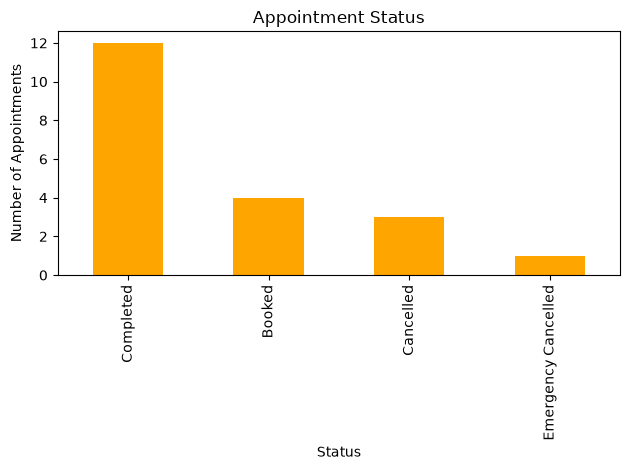

In [14]:
appointment_counts.plot(
    kind="bar",
    color=CHART_COLOR
)

plt.title("Appointment Status")
plt.xlabel("Status")
plt.ylabel("Number of Appointments")

plt.tight_layout()
plt.show()

### Insight

The appointment status analysis shows the number of completed, booked, cancelled, and emergency-cancelled appointments. This helps the hospital understand appointment utilization and cancellation patterns.

In [15]:
df["waiting_time_minutes"].mean().round(2)

np.float64(38.25)

In [16]:
dept_wait_time = df.groupby("department")["waiting_time_minutes"].mean().round(2)
dept_wait_time

department
Cardiology          40.14
General Medicine    35.14
Neurology           39.67
Name: waiting_time_minutes, dtype: float64

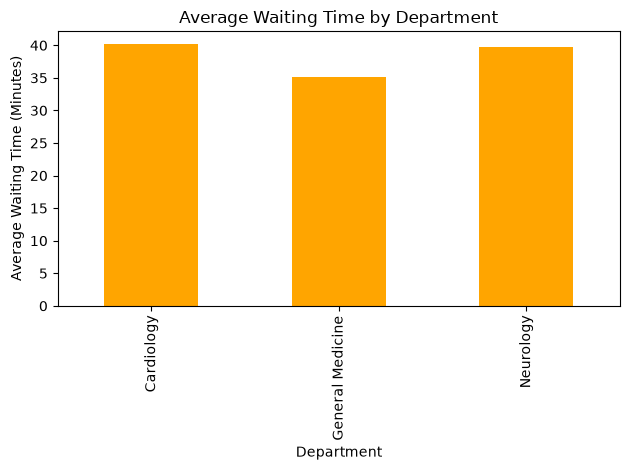

In [17]:
dept_wait_time.plot(
    kind="bar",
    color=CHART_COLOR
)

plt.title("Average Waiting Time by Department")
plt.xlabel("Department")
plt.ylabel("Average Waiting Time (Minutes)")

plt.tight_layout()
plt.show()

### Insight

The department-wise waiting-time analysis helps identify departments where patients experience longer waiting periods. This information can help hospital management understand where operational improvements may be required.

## 7. Laboratory Analysis

Laboratory results can be analyzed to understand the distribution of test results and identify records that may require further attention.

In [18]:
df.groupby("lab_test")["lab_result"].mean().round(2)

lab_test
Blood Test      13.80
Cholesterol    216.50
Glucose        163.06
Name: lab_result, dtype: float64

In [19]:
df["lab_test"].value_counts()

lab_test
Cholesterol    9
Glucose        7
Blood Test     4
Name: count, dtype: int64

In [20]:
df[[
    "patient_id",
    "lab_test",
    "lab_result",
    "diagnosis"
]]

,patient_id,lab_test,lab_result,diagnosis
0,2001,Glucose,169.5,Pre-Diabetes
1,2002,Cholesterol,233.2,High Cholesterol
2,2003,Cholesterol,199.7,High Cholesterol
3,2004,Glucose,180.2,Hypertension
4,2005,Glucose,179.9,Hypertension
5,2006,Blood Test,14.2,Migraine
6,2007,Cholesterol,194.6,Hypertension
7,2008,Cholesterol,229.2,Routine Checkup
8,2009,Cholesterol,208.1,Routine Checkup
9,2010,Blood Test,14.5,Anemia


## 8. Wearable Health Data Analysis

Wearable devices continuously generate health measurements. In this dataset, heart rate and SpO2 are used as examples of wearable measurements.

In a real system, this type of data could be processed using a streaming pipeline.

In [20]:
df[[
    "patient_id",
    "heart_rate",
    "spo2"
]].head()

,patient_id,heart_rate,spo2
0,2001,77,97
1,2002,102,92
2,2003,94,99
3,2004,105,98
4,2005,100,93


In [21]:
df["heart_rate"].describe()

count     20.000000
mean      99.150000
std       10.873798
min       77.000000
25%       93.750000
50%      100.500000
75%      105.500000
max      114.000000
Name: heart_rate, dtype: float64

In [22]:
df["spo2"].describe()

count    20.000000
mean     93.800000
std       3.518373
min      89.000000
25%      90.750000
50%      93.500000
75%      97.000000
max      99.000000
Name: spo2, dtype: float64

In [23]:
elevated_heart_rate = df[df["heart_rate"] > 100]

elevated_heart_rate[[
    "patient_id",
    "heart_rate",
    "spo2"
]]

,patient_id,heart_rate,spo2
1,2002,102,92
3,2004,105,98
5,2006,114,89
9,2010,113,97
10,2011,109,90
12,2013,107,93
14,2015,114,99
15,2016,105,97
16,2017,104,94
19,2020,101,94


In [24]:
low_oxygen = df[df["spo2"] < 95]

low_oxygen[[
    "patient_id",
    "heart_rate",
    "spo2"
]]

,patient_id,heart_rate,spo2
1,2002,102,92
4,2005,100,93
5,2006,114,89
6,2007,80,91
8,2009,93,89
10,2011,109,90
11,2012,100,90
12,2013,107,93
16,2017,104,94
17,2018,88,89


## 9. High-Risk Patient Identification

The integrated patient data can be used as input for identifying patients who may require additional attention.

For this demonstration, a simple rule-based risk score is created using age, heart rate, and SpO2. In a real hospital environment, a properly validated machine-learning model would be required.

In [25]:
df["risk_score"] = 0

df.loc[df["age"] >= 60, "risk_score"] += 1
df.loc[df["heart_rate"] > 100, "risk_score"] += 1
df.loc[df["spo2"] < 95, "risk_score"] += 1

In [27]:
risk_bins = [-1, 0, 1, 10]
risk_labels = ["Low", "Medium", "High"]

df["risk_level"] = pd.cut(
    df["risk_score"],
    bins=risk_bins,
    labels=risk_labels
)

df[[
    "patient_id",
    "age",
    "heart_rate",
    "spo2",
    "risk_score",
    "risk_level"
]]

,patient_id,age,heart_rate,spo2,risk_score,risk_level
0,2001,29,77,97,0,Low
1,2002,35,102,92,2,High
2,2003,76,94,99,1,Medium
3,2004,24,105,98,1,Medium
4,2005,68,100,93,2,High
5,2006,68,114,89,3,High
6,2007,76,80,91,2,High
7,2008,55,99,98,0,Low
8,2009,54,93,89,1,Medium
9,2010,69,113,97,2,High


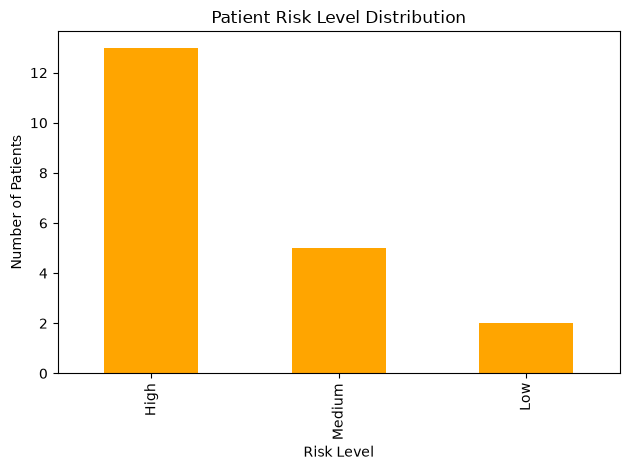

In [28]:
df["risk_level"].value_counts().plot(
    kind="bar",
    color=CHART_COLOR
)

plt.title("Patient Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

### Insight

The risk-level distribution gives hospital staff a quick view of how many patients currently fall into the low, medium, and high-risk categories, so attention can be prioritized accordingly.

## 10. Emergency Cancellation Analysis

Emergency cancellation is treated as an appointment event. When an emergency cancellation occurs, the affected appointment must be identified and the patient should be informed.

In a real application, the workflow would update the slot status, notify the affected patient, and provide alternative slots for rescheduling.

In [29]:
df[df["appointment_status"] == "Emergency Cancelled"]

,patient_id,patient_name,age,gender,department,doctor,appointment_date,scheduled_time,actual_consultation_time,appointment_status,lab_test,lab_result,spo2,heart_rate,diagnosis,waiting_time_minutes,risk_score,risk_level
11,2012,Priya,28,M,General Medicine,Dr. Verma,2026-09-21,2026-09-21 13:40:00,2026-09-21 14:16:00,Emergency Cancelled,Cholesterol,231.8,90,100,Hypertension,36.0,1,Medium


In [30]:
df["doctor"].value_counts()

doctor
Dr. Verma     7
Dr. Nair      7
Dr. Sharma    6
Name: count, dtype: int64

In [31]:
df.groupby("doctor")["appointment_status"].count()

doctor
Dr. Nair      7
Dr. Sharma    6
Dr. Verma     7
Name: appointment_status, dtype: int64

## 11. Summary Statistics

In [32]:
total_patients = df["patient_id"].nunique()
total_appointments = len(df)

completed = (df["appointment_status"] == "Completed").sum()

cancelled = df["appointment_status"].isin(
    ["Cancelled", "Emergency Cancelled"]
).sum()

average_waiting_time = df["waiting_time_minutes"].mean()

high_risk_patients = (df["risk_level"] == "High").sum()

print("Total Patients:", total_patients)
print("Total Appointments:", total_appointments)
print("Completed Appointments:", completed)
print("Cancelled Appointments:", cancelled)
print("Average Waiting Time:", round(average_waiting_time, 2), "minutes")
print("High-Risk Patients:", high_risk_patients)

Total Patients: 20
Total Appointments: 20
Completed Appointments: 12
Cancelled Appointments: 4
Average Waiting Time: 38.25 minutes
High-Risk Patients: 13


## 12. Final Conclusion

The hospital dataset was loaded, inspected, cleaned, transformed, and analyzed.

The analysis covered:

- Appointment status
- Department-wise waiting time
- Laboratory results
- Wearable health measurements
- Emergency cancellations
- Patient risk levels

The pipeline demonstrates how hospital data from different operational areas can be processed and transformed into useful information for hospital management.

In a production environment, the same approach can be extended using batch and streaming ingestion, a raw data repository, a data warehouse, automated monitoring, and a validated machine-learning model for high-risk patient prediction.